# Clustering Track — Review 2

## Problem Statement

Use customer demographic and spending information to discover customer segments with K-Means and Agglomerative Hierarchical Clustering. The analysis compares cluster quality using the required internal validation metrics and visualizes the assignments in two dimensions.

In [1]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display

warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')
np.random.seed(42)
print('Clustering setup completed')

Clustering setup completed


## 2. Load and audit the dataset

The dataset contains 200 customers and five columns: CustomerID, Gender, Age, Annual Income (k$), and Spending Score (1-100). CustomerID is an identifier and Gender is not used as a numeric clustering feature in this study.

In [2]:
df = pd.read_csv('../datasets/mall_customers.csv')
print('Dataset Shape:', df.shape)
print('\nData Types:')
print(df.dtypes)
print('\nMissing Values:')
print(df.isnull().sum())
print('\nDuplicate Rows:', df.duplicated().sum())
display(df.head())

Dataset Shape: (200, 5)

Data Types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


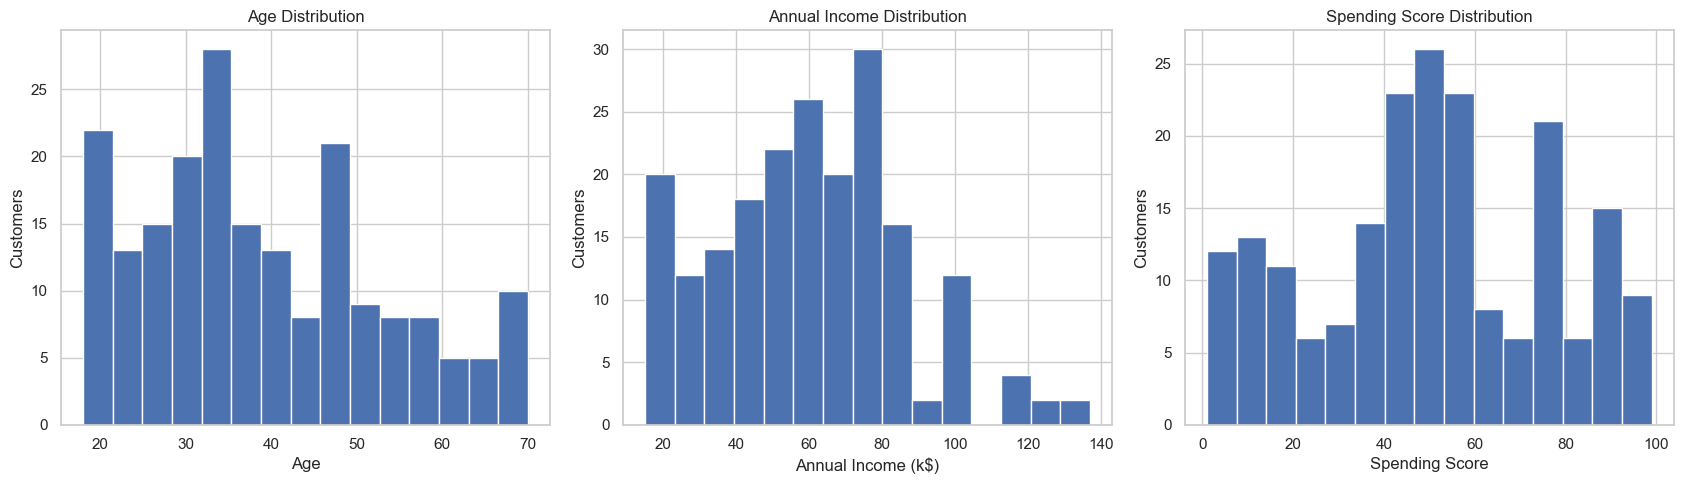

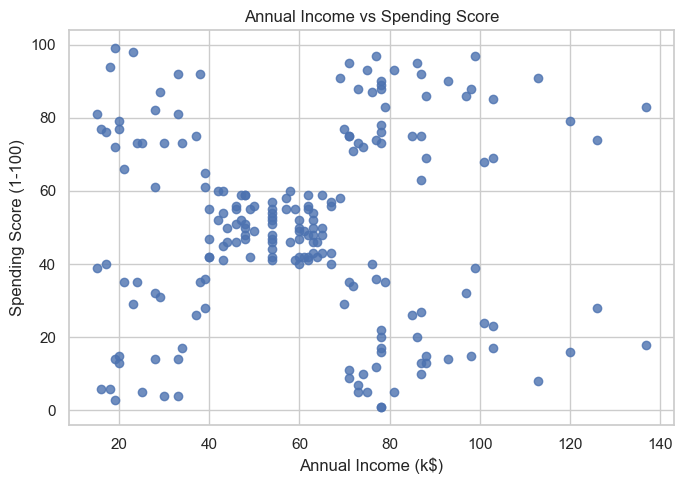

In [3]:
# 2.1 Basic EDA
fig, axes = plt.subplots(1,3,figsize=(17,5))
axes[0].hist(df['Age'], bins=15)
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Customers')
axes[1].hist(df['Annual Income (k$)'], bins=15)
axes[1].set_title('Annual Income Distribution')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Customers')
axes[2].hist(df['Spending Score (1-100)'], bins=15)
axes[2].set_title('Spending Score Distribution')
axes[2].set_xlabel('Spending Score')
axes[2].set_ylabel('Customers')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.8)
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

**Observation:** Age, annual income, and spending score have different numerical scales and ranges. Standardisation is therefore applied before distance-based clustering. Annual income and spending score also provide a direct view of customer purchasing behaviour.

## 3. Preprocessing and feature selection

CustomerID is removed because it is an identifier rather than a behavioural measurement. Gender is retained in the raw dataset for reference but excluded from the clustering matrix. The three numeric behavioural/demographic variables are standardised before fitting both clustering algorithms.

In [4]:
features = ['Age','Annual Income (k$)','Spending Score (1-100)']
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

processed = df[['CustomerID','Gender'] + features].copy()
for i,col in enumerate(features):
    processed[col+'_Scaled'] = X_scaled[:,i]
processed.to_csv('../datasets/mall_customers_preprocessed.csv', index=False)

print('Clustering feature matrix shape:', X_scaled.shape)
print('Scaled means:', np.round(X_scaled.mean(axis=0),4))
print('Scaled standard deviations:', np.round(X_scaled.std(axis=0),4))

Clustering feature matrix shape: (200, 3)
Scaled means: [-0. -0. -0.]
Scaled standard deviations: [1. 1. 1.]


## 4. K-Means: Elbow method

The Elbow curve is used to inspect how within-cluster sum of squares (inertia) changes with the number of clusters.

,k,Inertia,Silhouette
0,2,389.3862,0.3355
1,3,295.2122,0.3578
2,4,205.2251,0.4040
3,5,168.2476,0.4166
4,6,133.8684,0.4284
5,7,117.0116,0.4172
6,8,103.8733,0.4082
7,9,93.0929,0.4177
8,10,82.3852,0.4066


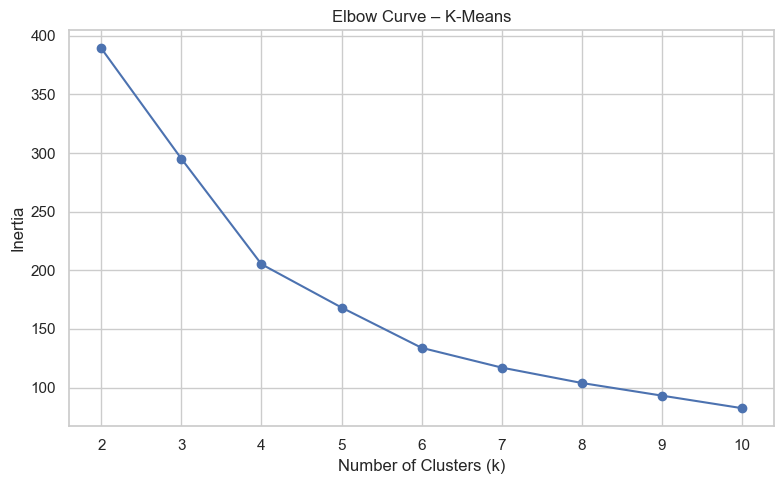

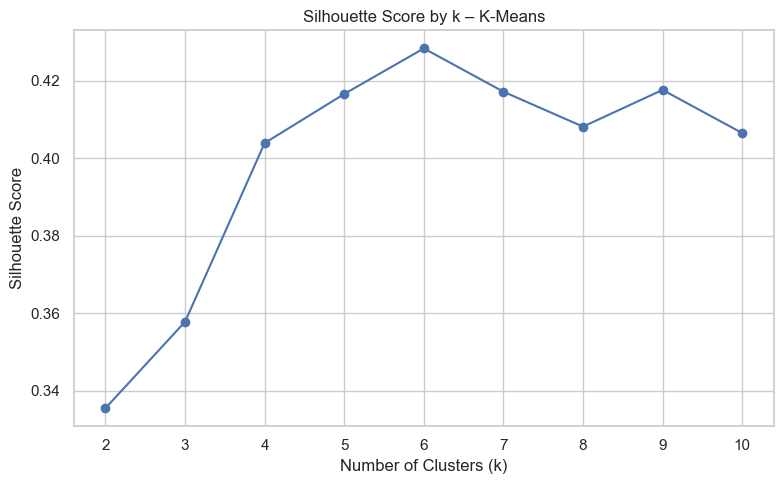

In [5]:
k_values = range(2,11)
inertias=[]
silhouette_values=[]
for k in k_values:
    model=KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels=model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

elbow_table=pd.DataFrame({'k':list(k_values),'Inertia':inertias,'Silhouette':silhouette_values})
display(elbow_table.round(4))

plt.figure(figsize=(8,5))
plt.plot(list(k_values), inertias, marker='o')
plt.title('Elbow Curve – K-Means')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(list(k_values), silhouette_values, marker='o')
plt.title('Silhouette Score by k – K-Means')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

**K selection:** The notebook reports both inertia and silhouette values for k=2 to 10. For this dataset, k=6 is used for the final algorithm comparison because it gives a clear segmentation structure while also providing a strong internal validation score.

In [6]:
chosen_k=6
kmeans=KMeans(n_clusters=chosen_k, init='k-means++', random_state=42, n_init=10)
kmeans_labels=kmeans.fit_predict(X_scaled)
print('K-Means cluster counts:')
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means cluster counts:
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


## 5. Agglomerative Hierarchical Clustering

A Ward-linkage dendrogram is shown to examine hierarchical grouping before fitting the final Agglomerative model.

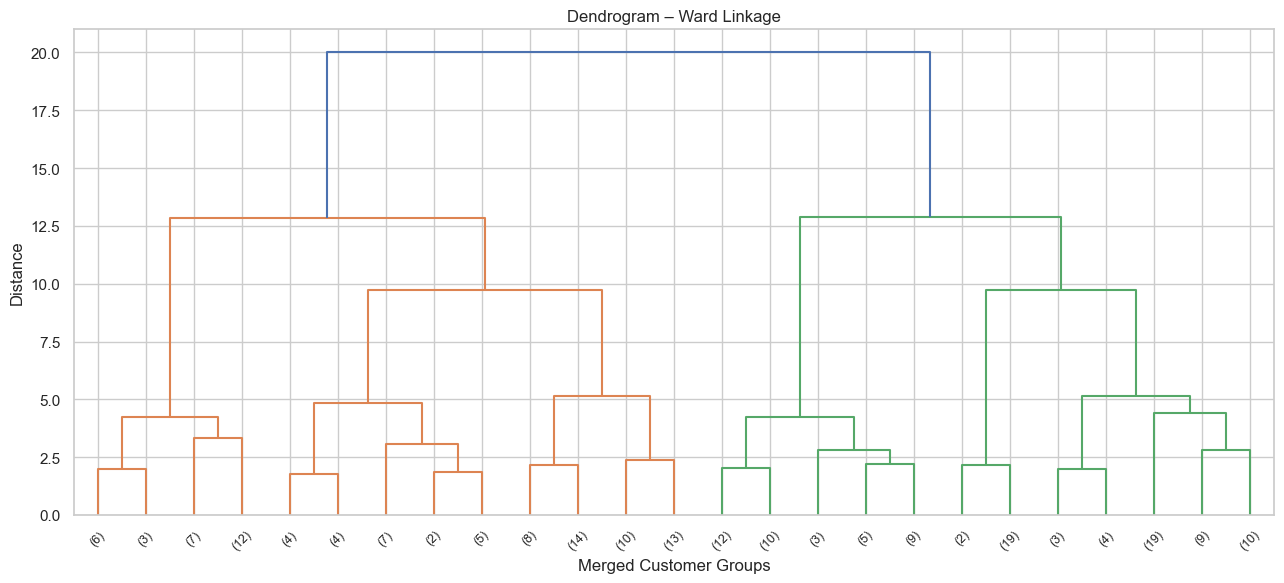

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,ward,0.4201,0.8521,127.9865
1,complete,0.3746,1.0005,109.4154
2,average,0.3896,0.8646,102.0370


Agglomerative cluster counts:
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64


In [7]:
Z=linkage(X_scaled, method='ward')
plt.figure(figsize=(13,6))
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=9)
plt.title('Dendrogram – Ward Linkage')
plt.xlabel('Merged Customer Groups')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

linkage_methods=['ward','complete','average']
linkage_rows=[]
for method in linkage_methods:
    model=AgglomerativeClustering(n_clusters=chosen_k, linkage=method)
    labels=model.fit_predict(X_scaled)
    linkage_rows.append({
        'Linkage':method,
        'Silhouette':silhouette_score(X_scaled,labels),
        'Davies-Bouldin':davies_bouldin_score(X_scaled,labels),
        'Calinski-Harabasz':calinski_harabasz_score(X_scaled,labels)
    })
linkage_table=pd.DataFrame(linkage_rows)
display(linkage_table.round(4))

agglomerative=AgglomerativeClustering(n_clusters=chosen_k, linkage='ward')
agglomerative_labels=agglomerative.fit_predict(X_scaled)
print('Agglomerative cluster counts:')
print(pd.Series(agglomerative_labels).value_counts().sort_index())

## 6. Mandatory clustering evaluation metrics

The three required internal validation metrics are reported for both final algorithms. Higher Silhouette and Calinski-Harabasz values indicate more compact/separated cluster structure, while lower Davies-Bouldin values indicate lower average similarity between clusters.

In [8]:
def cluster_metrics(name, labels):
    return {
        'Algorithm':name,
        'Silhouette Score':silhouette_score(X_scaled,labels),
        'Davies-Bouldin Index':davies_bouldin_score(X_scaled,labels),
        'Calinski-Harabasz Index':calinski_harabasz_score(X_scaled,labels)
    }

cluster_comparison=pd.DataFrame([
    cluster_metrics('K-Means',kmeans_labels),
    cluster_metrics('Agglomerative Hierarchical (Ward)',agglomerative_labels)
])
display(cluster_comparison.round(4))
cluster_comparison.round(4).to_csv('../datasets/clustering_review2_comparison.csv',index=False)

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.4284,0.8254,135.1021
1,Agglomerative Hierarchical (Ward),0.4201,0.8521,127.9865


## 7. PCA 2D cluster visualisation

PCA is used only for visualisation. It does not replace the original three-feature clustering space used to fit the algorithms.

Explained variance ratio: [0.4427 0.3331]


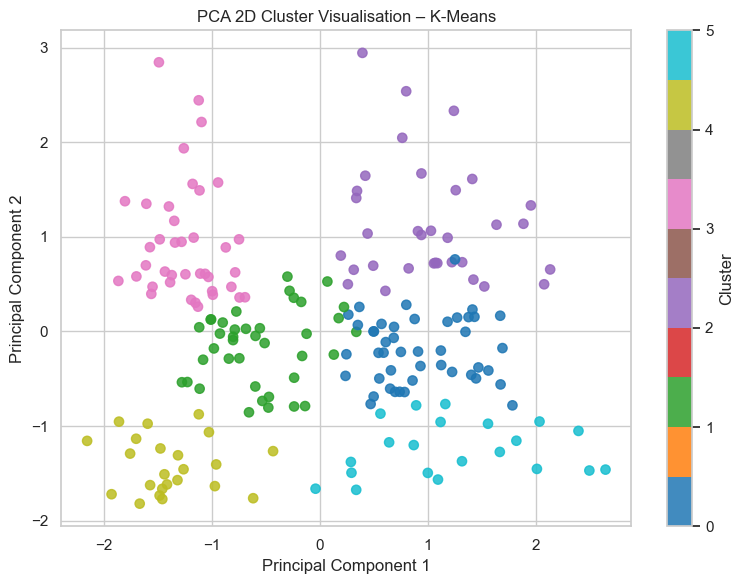

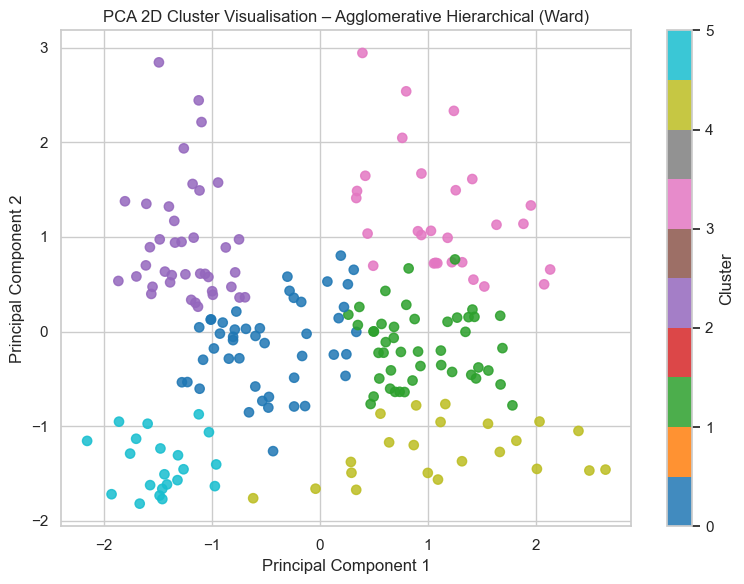

In [9]:
pca=PCA(n_components=2, random_state=42)
X_pca=pca.fit_transform(X_scaled)
print('Explained variance ratio:', np.round(pca.explained_variance_ratio_,4))

for name,labels in [('K-Means',kmeans_labels),('Agglomerative Hierarchical (Ward)',agglomerative_labels)]:
    plt.figure(figsize=(8,6))
    scatter=plt.scatter(X_pca[:,0],X_pca[:,1],c=labels,cmap='tab10',s=45,alpha=0.85)
    plt.title(f'PCA 2D Cluster Visualisation – {name}')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.colorbar(scatter,label='Cluster')
    plt.tight_layout()
    plt.show()

**Observation:** The PCA plots provide a two-dimensional view of the cluster assignments. PCA is a projection for visual interpretation, so separation seen in the plot should be considered together with the three internal validation metrics.

## 8. t-SNE visualisation

A t-SNE projection is included as the additional visualisation encouraged by the guideline. It is used only to inspect local neighbourhood structure and not to fit the clustering models.

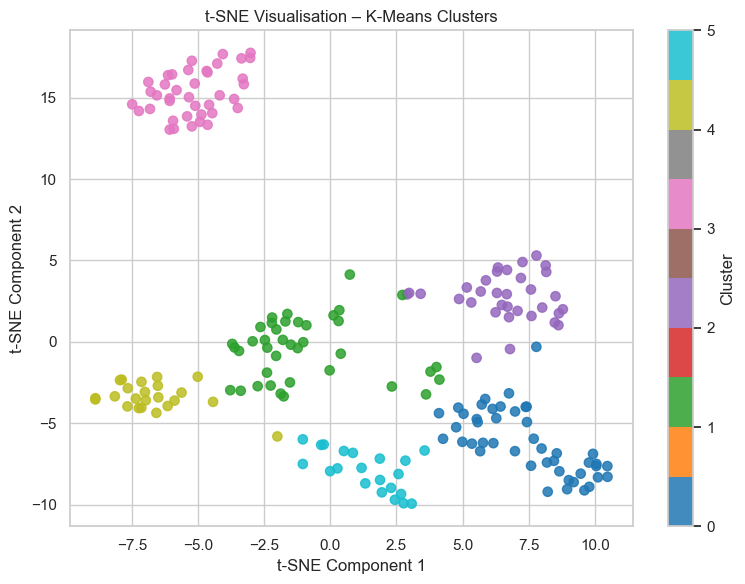

In [10]:
tsne=TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne=tsne.fit_transform(X_scaled)
plt.figure(figsize=(8,6))
scatter=plt.scatter(X_tsne[:,0],X_tsne[:,1],c=kmeans_labels,cmap='tab10',s=45,alpha=0.85)
plt.title('t-SNE Visualisation – K-Means Clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.colorbar(scatter,label='Cluster')
plt.tight_layout()
plt.show()

## 9. Cluster profiles

The following summaries describe the average feature values in each cluster. These profiles are descriptive; the cluster numbers themselves do not have an inherent order.

In [11]:
kmeans_profile=df[features].copy()
kmeans_profile['Cluster']=kmeans_labels
agg_profile=df[features].copy()
agg_profile['Cluster']=agglomerative_labels

print('K-Means Cluster Profile')
display(kmeans_profile.groupby('Cluster')[features].mean().round(2))
print('Agglomerative Cluster Profile')
display(agg_profile.groupby('Cluster')[features].mean().round(2))

profiles=pd.concat([
    kmeans_profile.groupby('Cluster')[features].mean().add_prefix('KMeans_'),
    agg_profile.groupby('Cluster')[features].mean().add_prefix('Agglomerative_')
],axis=1)
profiles.to_csv('../datasets/clustering_cluster_profiles.csv')

K-Means Cluster Profile


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


Agglomerative Cluster Profile


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,27.38,57.51,45.84
1,56.40,55.29,48.36
2,32.69,86.54,82.13
3,43.89,91.29,16.68
4,44.32,25.77,20.27
5,24.81,25.62,80.24
